In [2]:
# MULTI-UAV PATH PLANNING: FIRST WORKING PROTOTYPE
# 4 UAVs + A* + obstacles + collision detection + animation

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
import heapq

# --------------------------------------------------
# 1. ENVIRONMENT CONFIGURATION
# --------------------------------------------------

GRID_SIZE = 20
NUM_UAVS = 4

# 0 = free cell, 1 = obstacle
grid = np.zeros((GRID_SIZE, GRID_SIZE), dtype=int)

# Add static obstacles
obstacles = [
    (4, 4), (4, 5), (4, 6), (4, 7),
    (7, 10), (8, 10), (9, 10), (10, 10),
    (13, 3), (13, 4), (13, 5), (13, 6),
    (15, 13), (15, 14), (15, 15),
    (5, 15), (6, 15), (7, 15)
]

for r, c in obstacles:
    grid[r, c] = 1

# UAV starting positions: (row, column)
starts = [
    (1, 1),
    (1, 18),
    (18, 1),
    (18, 18)
]

goals = [
    (2, 8),
    (2, 12),
    (17, 8),
    (17, 12)
]

# Movement: 8 directions + stay
ACTIONS = [
    (-1, 0), (1, 0), (0, -1), (0, 1),
    (-1, -1), (-1, 1), (1, -1), (1, 1),
    (0, 0)
]

# --------------------------------------------------
# 2. A* PATH PLANNING
# --------------------------------------------------

def heuristic(a, b):
    """Octile distance for 8-directional movement."""
    dx = abs(a[0] - b[0])
    dy = abs(a[1] - b[1])
    return max(dx, dy) + (np.sqrt(2) - 1) * min(dx, dy)


def get_neighbors(position):
    r, c = position
    neighbors = []

    for dr, dc in ACTIONS[:-1]:  # Exclude stay
        nr, nc = r + dr, c + dc

        if not (0 <= nr < GRID_SIZE and 0 <= nc < GRID_SIZE):
            continue

        if grid[nr, nc] == 1:
            continue

        # Prevent diagonal corner-cutting through obstacles
        if dr != 0 and dc != 0:
            if grid[r + dr, c] == 1 or grid[r, c + dc] == 1:
                continue

        cost = np.sqrt(2) if dr != 0 and dc != 0 else 1
        neighbors.append(((nr, nc), cost))

    return neighbors


def astar(start, goal):
    """Find a shortest path using A*."""

    open_set = []
    heapq.heappush(open_set, (0, start))

    came_from = {}
    g_score = {start: 0}

    while open_set:
        _, current = heapq.heappop(open_set)

        if current == goal:
            path = [current]
            while current in came_from:
                current = came_from[current]
                path.append(current)
            return path[::-1]

        for neighbor, move_cost in get_neighbors(current):
            tentative_g = g_score[current] + move_cost

            if tentative_g < g_score.get(neighbor, float("inf")):
                came_from[neighbor] = current
                g_score[neighbor] = tentative_g

                f_score = tentative_g + heuristic(neighbor, goal)
                heapq.heappush(open_set, (f_score, neighbor))

    return None


# Plan an independent A* path for every UAV
paths = []

for i in range(NUM_UAVS):
    path = astar(starts[i], goals[i])

    if path is None:
        raise ValueError(f"No path found for UAV {i+1}")

    paths.append(path)
    print(f"UAV {i+1}: Found path with {len(path)-1} moves")


# --------------------------------------------------
# 3. SIMULTANEOUS MOVEMENT + COLLISION DETECTION
# --------------------------------------------------

positions = list(starts)
path_indices = [0] * NUM_UAVS

# Store every UAV's position at each time step
histories = [[pos] for pos in positions]

collision_events = 0
MAX_STEPS = 250

for timestep in range(MAX_STEPS):

    if all(positions[i] == goals[i] for i in range(NUM_UAVS)):
        break

    # Each UAV proposes its next move
    proposals = []

    for i in range(NUM_UAVS):
        if positions[i] == goals[i]:
            proposals.append(positions[i])
        else:
            next_index = min(path_indices[i] + 1, len(paths[i]) - 1)
            proposals.append(paths[i][next_index])

    # Initially, all proposed movements are accepted
    blocked = [False] * NUM_UAVS

    # Resolve conflicts. Lower-index UAV gets priority.
    changed = True

    while changed:
        changed = False

        for i in range(NUM_UAVS):
            for j in range(i + 1, NUM_UAVS):

                # Two UAVs trying to occupy the same cell
                same_cell = proposals[i] == proposals[j]

                # Two UAVs attempting to swap positions
                swapping = (
                    proposals[i] == positions[j]
                    and proposals[j] == positions[i]
                )

                if same_cell or swapping:
                    if not blocked[j]:
                        blocked[j] = True
                        changed = True

        # Don't enter a cell occupied by a UAV that will stay there
        for i in range(NUM_UAVS):
            if blocked[i]:
                continue

            for j in range(NUM_UAVS):
                if i == j:
                    continue

                if blocked[j] and proposals[i] == positions[j]:
                    blocked[i] = True
                    changed = True

    # Apply all accepted moves simultaneously
    new_positions = [
        positions[i] if blocked[i] else proposals[i]
        for i in range(NUM_UAVS)
    ]

    # Count attempted conflicts, but not ordinary waiting
    collision_events += sum(blocked)

    for i in range(NUM_UAVS):
        if not blocked[i] and new_positions[i] != positions[i]:
            path_indices[i] += 1

    positions = new_positions

    for i in range(NUM_UAVS):
        histories[i].append(positions[i])

print("\nSimulation completed.")
print("Time steps:", len(histories[0]) - 1)
print("Collision-conflict events avoided:", collision_events)

for i in range(NUM_UAVS):
    print(
        f"UAV {i+1}: {positions[i]} | "
        f"Goal: {goals[i]} | "
        f"Reached: {positions[i] == goals[i]}"
    )


# --------------------------------------------------
# 4. VISUALIZATION / ANIMATION
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 9))

colors = ["red", "blue", "green", "orange"]

def update(frame):

    ax.clear()

    ax.set_xlim(-0.5, GRID_SIZE - 0.5)
    ax.set_ylim(GRID_SIZE - 0.5, -0.5)

    ax.set_xticks(range(GRID_SIZE))
    ax.set_yticks(range(GRID_SIZE))
    ax.grid(True, alpha=0.25)

    ax.set_title(
        f"Multi-UAV Path Planning | Time Step: {frame}",
        fontsize=14
    )

    # Draw obstacles
    obstacle_rows, obstacle_cols = np.where(grid == 1)
    ax.scatter(
        obstacle_cols, obstacle_rows,
        marker="s", s=150, color="black",
        label="Obstacles"
    )

    # Draw UAV paths and current positions
    for i in range(NUM_UAVS):

        history = histories[i][:frame + 1]

        rows = [p[0] for p in history]
        cols = [p[1] for p in history]

        ax.plot(
            cols, rows,
            color=colors[i],
            linewidth=2,
            alpha=0.65
        )

        current = histories[i][min(frame, len(histories[i])-1)]

        ax.scatter(
            current[1], current[0],
            color=colors[i],
            s=180,
            marker="o",
            edgecolors="black",
            label=f"UAV {i+1}"
        )

        # Draw goal
        ax.scatter(
            goals[i][1], goals[i][0],
            color=colors[i],
            s=160,
            marker="*",
            edgecolors="black"
        )

        ax.text(
            goals[i][1] + 0.2,
            goals[i][0] - 0.3,
            f"G{i+1}",
            fontsize=9
        )

    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.06),
              ncol=5)

animation = FuncAnimation(
    fig,
    update,
    frames=max(len(h) for h in histories),
    interval=350,
    repeat=False
)

plt.close(fig)
display(HTML(animation.to_jshtml()))

UAV 1: Found path with 7 moves
UAV 2: Found path with 6 moves
UAV 3: Found path with 7 moves
UAV 4: Found path with 6 moves

Simulation completed.
Time steps: 7
Collision-conflict events avoided: 0
UAV 1: (2, 8) | Goal: (2, 8) | Reached: True
UAV 2: (2, 12) | Goal: (2, 12) | Reached: True
UAV 3: (17, 8) | Goal: (17, 8) | Reached: True
UAV 4: (17, 12) | Goal: (17, 12) | Reached: True


In [3]:
# CHALLENGING MULTI-UAV CROSSING SCENARIO

starts = [
    (1, 1),
    (1, 18),
    (18, 1),
    (18, 18)
]

goals = [
    (18, 18),
    (18, 1),
    (1, 18),
    (1, 1)
]

print("New crossing scenario created!")
for i in range(4):
    print(f"UAV {i+1}: {starts[i]} -> {goals[i]}")

New crossing scenario created!
UAV 1: (1, 1) -> (18, 18)
UAV 2: (1, 18) -> (18, 1)
UAV 3: (18, 1) -> (1, 18)
UAV 4: (18, 18) -> (1, 1)


In [4]:
# SPACE-TIME A* FOR COOPERATIVE MULTI-UAV PATH PLANNING

import heapq
import math
from collections import defaultdict

# Reserve (time, row, col) for each planned UAV
reservations = set()
edge_reservations = set()

def space_time_astar(start, goal, reservations, edge_reservations,
                     max_time=150):

    # State = (row, col, time)
    initial = (start[0], start[1], 0)

    queue = [(0, 0, initial)]
    parent = {}
    cost = {initial: 0}

    while queue:
        _, _, current = heapq.heappop(queue)

        r, c, t = current

        if (r, c) == goal:
            path = [current]
            while current in parent:
                current = parent[current]
                path.append(current)
            return path[::-1]

        if t >= max_time:
            continue

        for dr, dc in ACTIONS:
            nr, nc = r + dr, c + dc
            nt = t + 1

            if not (0 <= nr < GRID_SIZE and 0 <= nc < GRID_SIZE):
                continue

            if grid[nr, nc] == 1:
                continue

            if dr != 0 and dc != 0:
                if grid[r + dr, c] == 1 or grid[r, c + dc] == 1:
                    continue

            # Avoid entering a reserved cell
            if (nt, nr, nc) in reservations:
                continue

            # Avoid swapping positions with another UAV
            if (t, nr, nc, r, c) in edge_reservations:
                continue

            next_state = (nr, nc, nt)
            move_cost = math.sqrt(2) if dr and dc else 1

            new_cost = cost[current] + move_cost

            if new_cost < cost.get(next_state, float("inf")):
                cost[next_state] = new_cost
                parent[next_state] = current

                priority = new_cost + heuristic((nr, nc), goal)

                heapq.heappush(
                    queue,
                    (priority, nt, next_state)
                )

    return None


# Plan UAVs sequentially with reservations
cooperative_paths = []

for i in range(NUM_UAVS):

    path = space_time_astar(
        starts[i],
        goals[i],
        reservations,
        edge_reservations
    )

    if path is None:
        print(f"UAV {i+1}: No conflict-free path found.")
        break

    cooperative_paths.append(path)

    # Reserve every occupied cell at its corresponding time
    for r, c, t in path:
        reservations.add((t, r, c))

    # Reserve movement edges to prevent swaps
    for k in range(len(path) - 1):
        r1, c1, t1 = path[k]
        r2, c2, t2 = path[k + 1]

        edge_reservations.add((t1, r1, c1, r2, c2))

    # Reserve goal occupancy indefinitely
    gr, gc = goal = goals[i]
    arrival_time = path[-1][2]

    for future_t in range(arrival_time + 1, 151):
        reservations.add((future_t, gr, gc))

    print(
        f"UAV {i+1}: Planned {len(path)-1} moves, "
        f"arrival time = {arrival_time}"
    )


# Check planning success
print("\nCooperative planning summary:")
print("Successfully planned:", len(cooperative_paths), "/", NUM_UAVS)

UAV 1: Planned 21 moves, arrival time = 21
UAV 2: Planned 21 moves, arrival time = 21
UAV 3: Planned 21 moves, arrival time = 21
UAV 4: Planned 21 moves, arrival time = 21

Cooperative planning summary:
Successfully planned: 4 / 4


In [5]:
# VALIDATE SPACE-TIME PATHS

vertex_conflicts = []
swap_conflicts = []
diagonal_conflicts = []

for i in range(len(cooperative_paths)):
    for j in range(i + 1, len(cooperative_paths)):

        p1 = cooperative_paths[i]
        p2 = cooperative_paths[j]

        # Check same-cell occupancy
        for a in p1:
            for b in p2:
                if a[2] == b[2] and a[:2] == b[:2]:
                    vertex_conflicts.append((i+1, j+1, a[2]))

        # Check edge swaps and diagonal crossings
        for k in range(min(len(p1), len(p2)) - 1):
            a1, a2 = p1[k], p1[k+1]
            b1, b2 = p2[k], p2[k+1]

            if a1[2] != b1[2]:
                continue

            if a1[:2] == b2[:2] and a2[:2] == b1[:2]:
                swap_conflicts.append((i+1, j+1, a1[2]))

            # Detect diagonal crossing through the same square
            if (a1[0]+a2[0] == b1[0]+b2[0] and
                a1[1]+a2[1] == b1[1]+b2[1] and
                a1[:2] != b1[:2] and
                a2[:2] != b2[:2] and
                abs(a2[0]-a1[0]) == 1 and
                abs(a2[1]-a1[1]) == 1 and
                abs(b2[0]-b1[0]) == 1 and
                abs(b2[1]-b1[1]) == 1):
                diagonal_conflicts.append((i+1, j+1, a1[2]))

print("Vertex conflicts:", vertex_conflicts)
print("Swap conflicts:", swap_conflicts)
print("Diagonal crossing conflicts:", diagonal_conflicts)

if not vertex_conflicts and not swap_conflicts and not diagonal_conflicts:
    print("\nAll tested conflicts avoided!")
else:
    print("\nConflicts detected. Planner needs improvement.")

Vertex conflicts: []
Swap conflicts: []
Diagonal crossing conflicts: []

All tested conflicts avoided!


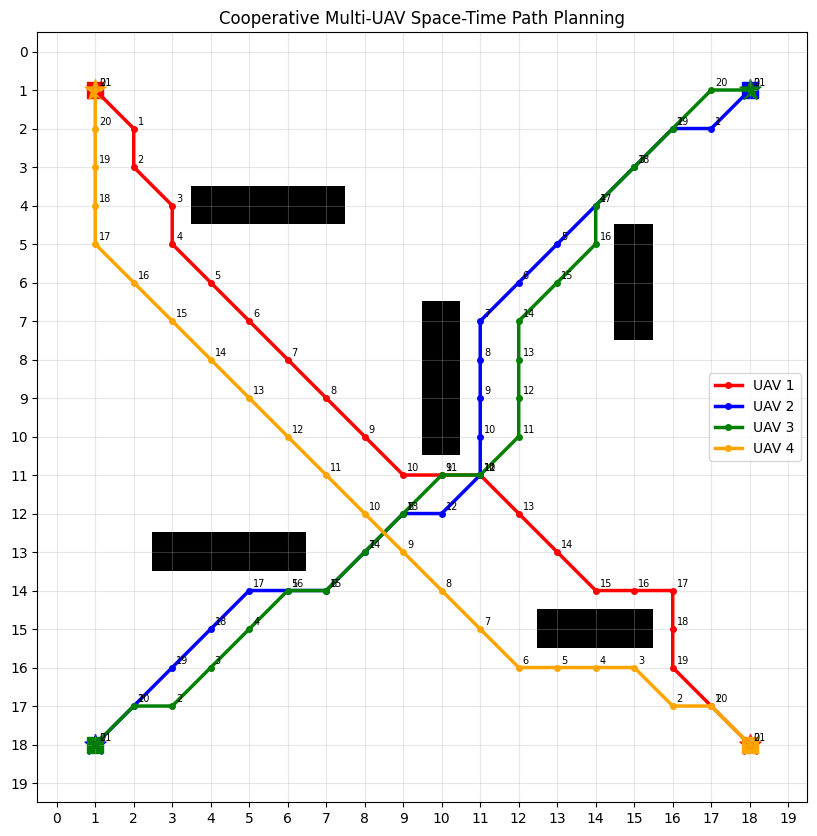

In [6]:
# VISUALIZE COOPERATIVE MULTI-UAV PATHS

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))

colors = ["red", "blue", "green", "orange"]

ax.imshow(grid, cmap="Greys", origin="upper")

for i, path in enumerate(cooperative_paths):

    rows = [p[0] for p in path]
    cols = [p[1] for p in path]

    # Draw trajectory
    ax.plot(
        cols, rows,
        color=colors[i],
        linewidth=2.5,
        marker="o",
        markersize=4,
        label=f"UAV {i+1}"
    )

    # Start position
    ax.scatter(
        starts[i][1], starts[i][0],
        color=colors[i], marker="s", s=130
    )

    # Destination
    ax.scatter(
        goals[i][1], goals[i][0],
        color=colors[i], marker="*", s=250
    )

    # Time labels
    for r, c, t in path:
        ax.text(c + 0.1, r - 0.1, str(t), fontsize=7)

ax.set_xticks(range(GRID_SIZE))
ax.set_yticks(range(GRID_SIZE))
ax.grid(alpha=0.3)

ax.set_title("Cooperative Multi-UAV Space-Time Path Planning")
ax.legend()
plt.show()

In [46]:
import numpy as np

class MultiUAVEnv:

    def __init__(self, grid, starts, goals, max_steps=100):
        self.grid = grid.copy()
        self.starts = list(starts)
        self.goals = list(goals)

        self.n_agents = len(starts)
        self.max_steps = max_steps

        self.actions = [
            (-1, 0), (1, 0), (0, -1), (0, 1),
            (-1, -1), (-1, 1), (1, -1), (1, 1),
            (0, 0)
        ]

        # Precompute obstacle-aware distance maps
        self.distance_maps = [
            compute_distance_map(self.grid, goal)
            for goal in self.goals
        ]

        self.reset()

    def reset(self):
        self.positions = list(self.starts)
        self.step_count = 0
        self.done_agents = [False] * self.n_agents

        return self.get_observations()

    def get_observations(self):
        observations = []

        for i in range(self.n_agents):
            r, c = self.positions[i]
            gr, gc = self.goals[i]

            obs = [
                r / (self.grid.shape[0] - 1),
                c / (self.grid.shape[1] - 1),
                gr / (self.grid.shape[0] - 1),
                gc / (self.grid.shape[1] - 1)
            ]

            # Relative positions of other UAVs
            for j in range(self.n_agents):
                if i == j:
                    continue

                orow, ocol = self.positions[j]

                obs.extend([
                    (orow - r) / self.grid.shape[0],
                    (ocol - c) / self.grid.shape[1]
                ])

            # Local 3x3 obstacle information
            for dr in [-1, 0, 1]:
                for dc in [-1, 0, 1]:

                    nr, nc = r + dr, c + dc

                    if (0 <= nr < self.grid.shape[0] and
                        0 <= nc < self.grid.shape[1]):

                        obs.append(float(self.grid[nr, nc]))
                    else:
                        obs.append(1.0)

            observations.append(
                np.array(obs, dtype=np.float32)
            )

        return observations

    def step(self, actions):

        self.step_count += 1

        old_positions = list(self.positions)
        proposals = []

        # Generate proposed movements
        for i, action in enumerate(actions):

            if self.done_agents[i]:
                proposals.append(old_positions[i])
                continue

            dr, dc = self.actions[int(action)]

            r, c = old_positions[i]
            nr, nc = r + dr, c + dc

            valid = (
                0 <= nr < self.grid.shape[0]
                and 0 <= nc < self.grid.shape[1]
                and self.grid[nr, nc] == 0
            )

            # Prevent diagonal corner cutting
            if valid and dr != 0 and dc != 0:
                if (self.grid[r + dr, c] == 1 or
                    self.grid[r, c + dc] == 1):
                    valid = False

            if not valid:
                nr, nc = r, c

            proposals.append((nr, nc))

        # ==========================================
        # COLLISION RESOLUTION
        # Same-cell, swap and diagonal crossings
        # ==========================================

        collisions = [False] * self.n_agents

        resolved_positions = proposals.copy()

        for i in range(self.n_agents):
            for j in range(i + 1, self.n_agents):

                a0 = old_positions[i]
                a1 = proposals[i]

                b0 = old_positions[j]
                b1 = proposals[j]

                # Same destination
                same_cell = a1 == b1

                # Direct position swap
                swapping = (a1 == b0 and b1 == a0)

                # Diagonal intersection:
                # Both UAVs traverse opposite diagonals
                diagonal_crossing = (
                    abs(a0[0] - a1[0]) == 1
                    and abs(a0[1] - a1[1]) == 1
                    and abs(b0[0] - b1[0]) == 1
                    and abs(b0[1] - b1[1]) == 1
                    and (
                        a0[0] + a1[0] == b0[0] + b1[0]
                    )
                    and (
                        a0[1] + a1[1] == b0[1] + b1[1]
                    )
                    and a0 != a1
                    and b0 != b1
                )

                if same_cell or swapping or diagonal_crossing:
                    collisions[i] = True
                    collisions[j] = True

        # Reject all movements involved in conflicts
        for i in range(self.n_agents):
            if collisions[i]:
                resolved_positions[i] = old_positions[i]

        self.positions = resolved_positions

        # Calculate rewards
        rewards = []

        for i in range(self.n_agents):

            reward = -1.0

            if collisions[i]:
                reward -= 20.0

            old_pos = old_positions[i]
            new_pos = self.positions[i]

            # Obstacle-aware progress reward
            old_distance = self.distance_maps[i][old_pos]
            new_distance = self.distance_maps[i][new_pos]

            progress_reward = 3.0 * (
                old_distance - new_distance
            )

            reward += progress_reward

            # Goal reached
            if new_pos == self.goals[i]:
                if not self.done_agents[i]:
                    reward += 100.0

                self.done_agents[i] = True

            rewards.append(reward)

        terminated = all(self.done_agents)
        truncated = self.step_count >= self.max_steps

        info = {
            "collisions": sum(collisions),
            "completed_agents": sum(self.done_agents)
        }

        return (
            self.get_observations(),
            np.array(rewards, dtype=np.float32),
            terminated,
            truncated,
            info
        )

    def get_global_state(self):

        state = []

        for i in range(self.n_agents):
            state.extend(self.positions[i])
            state.extend(self.goals[i])

        return np.array(state, dtype=np.float32)

In [47]:
# Two UAVs moving diagonally across the same intersection

# Configure a dedicated test environment matching our test coordinates to ensure valid distance maps
test_starts = [
    (5, 5),
    (5, 6),
    (15, 15),
    (15, 16)
]
test_goals = [
    (6, 6),
    (6, 5),
    (15, 15),
    (15, 16)
]

test_env = MultiUAVEnv(grid, test_starts, test_goals)
test_env.reset()

# UAV 1: down-right (action 7)
# UAV 2: down-left (action 6)
# UAVs 3 and 4: stay (action 8)
test_actions = [7, 6, 8, 8]

old_positions = test_env.positions.copy()

_, rewards, terminated, truncated, info = test_env.step(test_actions)

print("Old positions:", old_positions)
print("New positions:", test_env.positions)
print("Collision information:", info)

assert info["collisions"] >= 2, "Diagonal crossing was not detected!"

print("\nDiagonal crossing test PASSED!")

Old positions: [(5, 5), (5, 6), (15, 15), (15, 16)]
New positions: [(5, 5), (5, 6), (15, 15), (15, 16)]
Collision information: {'collisions': 2, 'completed_agents': 2}

Diagonal crossing test PASSED!


In [48]:
# Reinitialize the environment with the original scenario
env = MultiUAVEnv(
    grid,
    starts,
    goals,
    max_steps=100
)

observations = env.reset()

print("Initial positions:", env.positions)
print("Goals:", env.goals)
print("Observation dimension:", len(observations[0]))
print("Global state dimension:", len(env.get_global_state()))
print("Distance maps:", len(env.distance_maps))

assert env.positions == list(starts)
assert len(observations[0]) == 19
assert len(env.get_global_state()) == 16

print("\nEnvironment ready for MAPPO retraining!")

Initial positions: [(1, 1), (1, 18), (18, 1), (18, 18)]
Goals: [(18, 18), (18, 1), (1, 18), (1, 1)]
Observation dimension: 19
Global state dimension: 16
Distance maps: 4

Environment ready for MAPPO retraining!


In [49]:
print("Actor:", actor)
print("Critic:", critic)

print("\nActor optimizer:", actor_optimizer)
print("Critic optimizer:", critic_optimizer)

print("\nDevice:", device)
print("Environment agents:", env.n_agents)
print("Observation dimension:", len(env.reset()[0]))
print("Global state dimension:", len(env.get_global_state()))

Actor: Actor(
  (network): Sequential(
    (0): Linear(in_features=19, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=9, bias=True)
  )
)
Critic: Critic(
  (network): Sequential(
    (0): Linear(in_features=16, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=1, bias=True)
  )
)

Actor optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0003
    maximize: False
    weight_decay: 0
)
Critic optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
   

In [51]:
env = MultiUAVEnv(grid, starts, goals, max_steps=100)

observations = env.reset()

print("Initial positions:", env.positions)
print("Goals:", env.goals)

Initial positions: [(1, 1), (1, 18), (18, 1), (18, 18)]
Goals: [(18, 18), (18, 1), (1, 18), (1, 1)]


In [52]:

# ==========================================
# A*-GUIDED MULTI-UAV VALIDATION
# ==========================================

env.reset()

paths = [
    astar(starts[i], goals[i])
    for i in range(NUM_UAVS)
]

path_indices = [0] * NUM_UAVS

for step in range(100):

    actions = []

    for i in range(NUM_UAVS):

        if env.done_agents[i]:
            actions.append(8)
            continue

        current = env.positions[i]
        path = paths[i]

        if current in path:
            path_indices[i] = path.index(current)

        if path_indices[i] + 1 < len(path):

            next_pos = path[path_indices[i] + 1]

            dr = next_pos[0] - current[0]
            dc = next_pos[1] - current[1]

            actions.append(ACTIONS.index((dr, dc)))

        else:
            actions.append(8)

    observations, rewards, terminated, truncated, info = env.step(actions)

    print(
        f"Step {step+1}: "
        f"Positions={env.positions}, "
        f"Completed={info['completed_agents']}, "
        f"Collisions={info['collisions']}"
    )

    if terminated or truncated:
        break

print("\n========== FINAL RESULTS ==========")
print("Completed UAVs:", sum(env.done_agents), "/", NUM_UAVS)
print("Final positions:", env.positions)
print("Goals:", goals)


Step 1: Positions=[(2, 2), (2, 17), (17, 2), (17, 17)], Completed=0, Collisions=0
Step 2: Positions=[(3, 2), (2, 16), (17, 3), (16, 17)], Completed=0, Collisions=0
Step 3: Positions=[(4, 3), (3, 15), (16, 4), (15, 16)], Completed=0, Collisions=0
Step 4: Positions=[(5, 3), (4, 14), (15, 5), (14, 16)], Completed=0, Collisions=0
Step 5: Positions=[(6, 4), (5, 13), (14, 6), (13, 15)], Completed=0, Collisions=0
Step 6: Positions=[(7, 5), (6, 12), (14, 7), (12, 14)], Completed=0, Collisions=0
Step 7: Positions=[(8, 6), (7, 11), (13, 8), (11, 13)], Completed=0, Collisions=0
Step 8: Positions=[(9, 7), (8, 11), (12, 9), (11, 12)], Completed=0, Collisions=0
Step 9: Positions=[(10, 8), (9, 11), (11, 10), (11, 11)], Completed=0, Collisions=0
Step 10: Positions=[(11, 9), (10, 11), (11, 10), (11, 11)], Completed=0, Collisions=2
Step 11: Positions=[(11, 9), (10, 11), (11, 10), (11, 11)], Completed=0, Collisions=4
Step 12: Positions=[(11, 9), (10, 11), (11, 10), (11, 11)], Completed=0, Collisions=4
St

In [54]:
print("Checking prioritized space-time planner...")
import inspect
print(inspect.signature(space_time_astar))

space_time_paths = []

for i in range(NUM_UAVS):
    path = space_time_astar(
        grid,
        starts[i],
        goals[i],
        space_time_paths
    )

    space_time_paths.append(path)

    if path is None:
        print(f"UAV {i+1}: No coordinated path found")
    else:
        print(
            f"UAV {i+1}: "
            f"{len(path)-1} moves | "
            f"Start: {path[0]} | "
            f"Goal: {path[-1]}"
        )

Checking prioritized space-time planner...
(start, goal, reservations, edge_reservations, max_time=150)


TypeError: unhashable type: 'numpy.ndarray'

In [50]:

# ==========================================
# IMPROVED MAPPO TRAINING
# Shared Actor + Centralized Critic (CTDE)
# ==========================================

import numpy as np
import torch
import torch.nn.functional as F
from torch.distributions import Categorical

# Training parameters
NUM_EPISODES = 500
GAMMA = 0.99
GAE_LAMBDA = 0.95
CLIP_EPSILON = 0.2
PPO_EPOCHS = 5
ENTROPY_COEF = 0.01
VALUE_COEF = 0.5

# Fresh networks: old policy was trained using the old reward function
actor = Actor(obs_dim=19, action_dim=9).to(device)
critic = Critic(state_dim=16).to(device)

actor_optimizer = torch.optim.Adam(actor.parameters(), lr=3e-4)
critic_optimizer = torch.optim.Adam(critic.parameters(), lr=1e-3)

success_history = []
reward_history = []

for episode in range(NUM_EPISODES):

    observations = env.reset()

    episode_reward = 0
    success = False

    # Rollout storage
    obs_buffer = []
    state_buffer = []
    action_buffer = []
    logprob_buffer = []
    reward_buffer = []
    value_buffer = []
    terminated_buffer = []
    truncated_buffer = []

    for step in range(env.max_steps):

        obs_array = np.array(observations, dtype=np.float32)

        obs_tensor = torch.tensor(
            obs_array, dtype=torch.float32, device=device
        )

        # Save state BEFORE executing actions
        current_state = env.get_global_state().copy()

        state_tensor = torch.tensor(
            current_state, dtype=torch.float32, device=device
        )

        with torch.no_grad():
            distribution = actor(obs_tensor)
            actions = distribution.sample()
            log_probs = distribution.log_prob(actions)

            value = critic(state_tensor).squeeze()

        next_observations, rewards, terminated, truncated, info = (
            env.step(actions.cpu().numpy())
        )

        # Store aligned transition
        obs_buffer.append(obs_array)
        state_buffer.append(current_state)
        action_buffer.append(actions.cpu().numpy())
        logprob_buffer.append(log_probs.cpu().numpy())
        reward_buffer.append(float(np.mean(rewards)))
        value_buffer.append(float(value.item()))
        terminated_buffer.append(terminated)
        truncated_buffer.append(truncated)

        episode_reward += float(np.mean(rewards))
        observations = next_observations

        if terminated or truncated:
            success = terminated
            break

    # Bootstrap value for time-limit truncation
    if truncated and not terminated:
        with torch.no_grad():
            final_state = torch.tensor(
                env.get_global_state(),
                dtype=torch.float32,
                device=device
            )
            next_value = float(critic(final_state).item())
    else:
        next_value = 0.0

    # ======================================
    # GENERALIZED ADVANTAGE ESTIMATION
    # ======================================

    advantages = []
    gae = 0.0

    for t in reversed(range(len(reward_buffer))):

        if terminated_buffer[t]:
            bootstrap = 0.0
            continuation = 0.0
        elif t == len(reward_buffer) - 1:
            bootstrap = next_value
            continuation = 0.0
        else:
            bootstrap = value_buffer[t + 1]
            continuation = 1.0

        delta = (
            reward_buffer[t]
            + GAMMA * bootstrap
            - value_buffer[t]
        )

        gae = (
            delta
            + GAMMA * GAE_LAMBDA * continuation * gae
        )

        advantages.insert(0, gae)

    returns = np.array(advantages) + np.array(value_buffer)
    advantages = np.array(advantages, dtype=np.float32)

    # Convert rollout to tensors
    obs_tensor = torch.tensor(
        np.array(obs_buffer),
        dtype=torch.float32,
        device=device
    )

    state_tensor = torch.tensor(
        np.array(state_buffer),
        dtype=torch.float32,
        device=device
    )

    action_tensor = torch.tensor(
        np.array(action_buffer),
        dtype=torch.long,
        device=device
    )

    old_logprob_tensor = torch.tensor(
        np.array(logprob_buffer),
        dtype=torch.float32,
        device=device
    )

    advantage_tensor = torch.tensor(
        advantages,
        dtype=torch.float32,
        device=device
    )

    return_tensor = torch.tensor(
        returns,
        dtype=torch.float32,
        device=device
    )

    # Normalize advantages
    if len(advantage_tensor) > 1:
        advantage_tensor = (
            advantage_tensor - advantage_tensor.mean()
        ) / (advantage_tensor.std(unbiased=False) + 1e-8)

    # ======================================
    # PPO OPTIMIZATION
    # ======================================

    for _ in range(PPO_EPOCHS):

        distribution = actor(obs_tensor)

        new_logprobs = distribution.log_prob(action_tensor)
        entropy = distribution.entropy().mean()

        values = critic(state_tensor).squeeze(-1)

        log_ratio = new_logprobs - old_logprob_tensor
        ratios = torch.exp(log_ratio)

        # Same team advantage shared across agents
        agent_advantages = advantage_tensor.unsqueeze(1).expand_as(
            new_logprobs
        )

        surr1 = ratios * agent_advantages
        surr2 = torch.clamp(
            ratios,
            1 - CLIP_EPSILON,
            1 + CLIP_EPSILON
        ) * agent_advantages

        actor_loss = -torch.min(surr1, surr2).mean()
        actor_loss -= ENTROPY_COEF * entropy

        critic_loss = F.mse_loss(values, return_tensor)

        actor_optimizer.zero_grad()
        actor_loss.backward()
        torch.nn.utils.clip_grad_norm_(
            actor.parameters(), max_norm=0.5
        )
        actor_optimizer.step()

        critic_optimizer.zero_grad()
        (VALUE_COEF * critic_loss).backward()
        torch.nn.utils.clip_grad_norm_(
            critic.parameters(), max_norm=0.5
        )
        critic_optimizer.step()

    success_history.append(int(success))
    reward_history.append(episode_reward)

    if (episode + 1) % 50 == 0:
        recent_success = np.mean(success_history[-50:]) * 100
        recent_reward = np.mean(reward_history[-50:])

        print(
            f"Episode {episode+1}/{NUM_EPISODES} | "
            f"Average Reward: {recent_reward:.2f} | "
            f"Success Rate: {recent_success:.1f}%"
        )

print("\nMAPPO training completed!")


Episode 50/500 | Average Reward: -95.84 | Success Rate: 0.0%
Episode 100/500 | Average Reward: -93.48 | Success Rate: 0.0%
Episode 150/500 | Average Reward: -80.21 | Success Rate: 0.0%
Episode 200/500 | Average Reward: -74.34 | Success Rate: 0.0%
Episode 250/500 | Average Reward: -67.51 | Success Rate: 0.0%
Episode 300/500 | Average Reward: -55.05 | Success Rate: 0.0%
Episode 350/500 | Average Reward: -44.02 | Success Rate: 0.0%


KeyboardInterrupt: 

In [34]:
NUM_TEST_EPISODES = 20

success_counts = []
completion_counts = []
collision_counts = []

for episode in range(NUM_TEST_EPISODES):

    observations = env.reset()
    total_collisions = 0

    for step in range(env.max_steps):

        obs_tensor = torch.tensor(
            np.array(observations),
            dtype=torch.float32,
            device=device
        )

        with torch.no_grad():
            distribution = actor(obs_tensor)
            actions = distribution.sample()

        observations, rewards, terminated, truncated, info = env.step(
            actions.cpu().numpy()
        )

        total_collisions += info["collisions"]

        if terminated or truncated:
            break

    completed = sum(env.done_agents)

    completion_counts.append(completed)
    success_counts.append(int(completed == NUM_UAVS))
    collision_counts.append(total_collisions)

print("========== DIAGNOSTIC EVALUATION ==========")
print("Episodes:", NUM_TEST_EPISODES)
print("Average UAVs completed:", np.mean(completion_counts))
print("Team success rate:", np.mean(success_counts) * 100, "%")
print("Average collisions:", np.mean(collision_counts))
print("Completion distribution:")

for i in range(NUM_UAVS + 1):
    print(f"{i} UAVs completed: {completion_counts.count(i)} episodes")

========== DIAGNOSTIC EVALUATION ==========
Episodes: 20
Average UAVs completed: 0.15
Team success rate: 0.0 %
Average collisions: 2.8
Completion distribution:
0 UAVs completed: 17 episodes
1 UAVs completed: 3 episodes
2 UAVs completed: 0 episodes
3 UAVs completed: 0 episodes
4 UAVs completed: 0 episodes


In [35]:

env.reset()

paths = [
    astar(starts[i], goals[i])
    for i in range(NUM_UAVS)
]

path_indices = [0] * NUM_UAVS

print("Initial positions:", env.positions)

for step in range(30):

    actions = []

    for i in range(NUM_UAVS):

        if env.done_agents[i]:
            actions.append(8)
            continue

        current = env.positions[i]
        path = paths[i]

        # Find the current position in the planned path
        if current in path:
            idx = path.index(current)
            path_indices[i] = idx

        if path_indices[i] + 1 < len(path):
            next_pos = path[path_indices[i] + 1]

            dr = next_pos[0] - current[0]
            dc = next_pos[1] - current[1]

            actions.append(ACTIONS.index((dr, dc)))
        else:
            actions.append(8)

    observations, rewards, terminated, truncated, info = env.step(actions)

    print(
        f"Step {step+1}: "
        f"Positions={env.positions}, "
        f"Completed={info['completed_agents']}, "
        f"Collisions={info['collisions']}"
    )

    if terminated or truncated:
        break

print("\nFinal completed UAVs:", sum(env.done_agents))


Initial positions: [(1, 1), (1, 18), (18, 1), (18, 18)]
Step 1: Positions=[(2, 2), (2, 17), (17, 2), (17, 17)], Completed=0, Collisions=0
Step 2: Positions=[(3, 2), (2, 16), (17, 3), (16, 17)], Completed=0, Collisions=0
Step 3: Positions=[(4, 3), (3, 15), (16, 4), (15, 16)], Completed=0, Collisions=0
Step 4: Positions=[(5, 3), (4, 14), (15, 5), (14, 16)], Completed=0, Collisions=0
Step 5: Positions=[(6, 4), (5, 13), (14, 6), (13, 15)], Completed=0, Collisions=0
Step 6: Positions=[(7, 5), (6, 12), (14, 7), (12, 14)], Completed=0, Collisions=0
Step 7: Positions=[(8, 6), (7, 11), (13, 8), (11, 13)], Completed=0, Collisions=0
Step 8: Positions=[(9, 7), (8, 11), (12, 9), (11, 12)], Completed=0, Collisions=0
Step 9: Positions=[(10, 8), (9, 11), (11, 10), (11, 11)], Completed=0, Collisions=0
Step 10: Positions=[(11, 9), (10, 11), (11, 10), (11, 11)], Completed=0, Collisions=2
Step 11: Positions=[(11, 9), (10, 11), (11, 10), (11, 11)], Completed=0, Collisions=4
Step 12: Positions=[(11, 9), (10

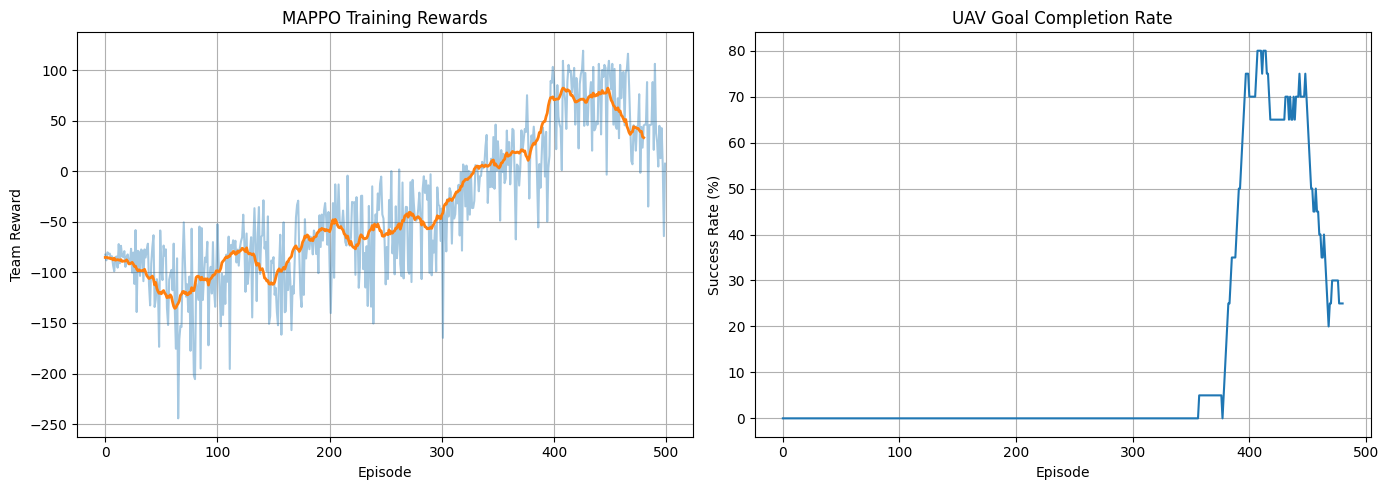

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Reward curve
axes[0].plot(episode_rewards, alpha=0.4)

if len(episode_rewards) >= 20:
    moving_avg = np.convolve(
        episode_rewards,
        np.ones(20)/20,
        mode="valid"
    )

    axes[0].plot(moving_avg, linewidth=2)

axes[0].set_title("MAPPO Training Rewards")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Team Reward")
axes[0].grid()

# Success rate
window = 20

success_avg = np.convolve(
    success_history,
    np.ones(window)/window,
    mode="valid"
) * 100

axes[1].plot(success_avg)
axes[1].set_title("UAV Goal Completion Rate")
axes[1].set_xlabel("Episode")
axes[1].set_ylabel("Success Rate (%)")
axes[1].grid()

plt.tight_layout()
plt.show()

In [12]:
# ============================================
# MAPPO EVALUATION - 100 EPISODES
# ============================================

NUM_TEST_EPISODES = 100

test_success = []
test_rewards = []
test_collisions = []
test_lengths = []

for episode in range(NUM_TEST_EPISODES):

    observations = env.reset()

    total_reward = 0
    total_collisions = 0

    for step in range(env.max_steps):

        obs_tensor = torch.tensor(
            np.array(observations),
            dtype=torch.float32,
            device=device
        )

        # Greedy action selection (no exploration)
        with torch.no_grad():
            distribution = actor(obs_tensor)
            actions = torch.argmax(
                distribution.probs, dim=-1
            )

        observations, rewards, terminated, truncated, info = env.step(
            actions.cpu().numpy()
        )

        total_reward += np.mean(rewards)
        total_collisions += info["collisions"]

        if terminated or truncated:
            break

    success = all(
        env.positions[i] == goals[i]
        for i in range(NUM_UAVS)
    )

    test_success.append(int(success))
    test_rewards.append(total_reward)
    test_collisions.append(total_collisions)
    test_lengths.append(step + 1)


print("========== MAPPO EVALUATION ==========")
print("Test episodes:", NUM_TEST_EPISODES)
print("Team success rate:", np.mean(test_success) * 100, "%")
print("Average reward:", np.mean(test_rewards))
print("Average collisions:", np.mean(test_collisions))
print("Average episode length:", np.mean(test_lengths))

========== MAPPO EVALUATION ==========
Test episodes: 100
Team success rate: 0.0 %
Average reward: -44.473717
Average collisions: 0.0
Average episode length: 100.0


In [13]:
# DIAGNOSE TRAINED MAPPO POLICY

observations = env.reset()

print("Initial positions:", env.positions)

for step in range(20):

    obs_tensor = torch.tensor(
        np.array(observations),
        dtype=torch.float32,
        device=device
    )

    with torch.no_grad():
        distribution = actor(obs_tensor)

        greedy_actions = torch.argmax(
            distribution.probs, dim=-1
        )

    print(f"\nStep {step + 1}")

    print("Actions:", greedy_actions.cpu().numpy())

    print("Action probabilities:")
    print(distribution.probs.cpu().numpy().round(2))

    observations, rewards, terminated, truncated, info = env.step(
        greedy_actions.cpu().numpy()
    )

    print("Positions:", env.positions)
    print("Rewards:", rewards)

    if terminated or truncated:
        break

Initial positions: [(1, 1), (1, 18), (18, 1), (18, 18)]

Step 1
Actions: [7 7 4 4]
Action probabilities:
[[0.01 0.25 0.08 0.06 0.02 0.03 0.05 0.45 0.05]
 [0.   0.29 0.01 0.03 0.01 0.   0.2  0.45 0.  ]
 [0.14 0.08 0.22 0.06 0.23 0.07 0.05 0.06 0.09]
 [0.09 0.   0.01 0.   0.89 0.01 0.   0.   0.  ]]
Positions: [(2, 2), (2, 19), (17, 0), (17, 17)]
Rewards: [ 3.2426407 -1.1246758 -1.1246758  3.2426407]

Step 2
Actions: [7 6 5 4]
Action probabilities:
[[0.01 0.24 0.07 0.07 0.02 0.03 0.04 0.47 0.05]
 [0.   0.   0.   0.   0.08 0.   0.91 0.   0.  ]
 [0.12 0.09 0.09 0.17 0.08 0.24 0.01 0.15 0.05]
 [0.09 0.   0.01 0.   0.89 0.01 0.   0.   0.  ]]
Positions: [(3, 3), (3, 18), (16, 1), (16, 16)]
Rewards: [3.2426407 3.2348633 3.2348633 3.2426407]

Step 3
Actions: [7 7 4 4]
Action probabilities:
[[0.02 0.25 0.1  0.07 0.03 0.03 0.06 0.38 0.06]
 [0.   0.28 0.01 0.03 0.01 0.   0.26 0.4  0.  ]
 [0.15 0.08 0.21 0.06 0.22 0.08 0.05 0.06 0.09]
 [0.21 0.01 0.02 0.03 0.62 0.09 0.01 0.   0.  ]]
Positions: [(3, 

In [14]:
observations = env.reset()

print("Initial positions:", env.positions)
print("Goals:", goals)

for step in range(10):

    obs_tensor = torch.tensor(
        np.array(observations),
        dtype=torch.float32,
        device=device
    )

    with torch.no_grad():
        distribution = actor(obs_tensor)
        actions = torch.argmax(distribution.probs, dim=-1)

    old_positions = env.positions.copy()

    observations, rewards, terminated, truncated, info = env.step(
        actions.cpu().numpy()
    )

    print(f"\nStep {step + 1}")

    for i in range(NUM_UAVS):
        print(
            f"UAV {i+1}: "
            f"{old_positions[i]} -> {env.positions[i]} | "
            f"Goal: {goals[i]} | "
            f"Action: {actions[i].item()} | "
            f"Reward: {rewards[i]:.2f}"
        )

    if terminated or truncated:
        break

Initial positions: [(1, 1), (1, 18), (18, 1), (18, 18)]
Goals: [(18, 18), (18, 1), (1, 18), (1, 1)]

Step 1
UAV 1: (1, 1) -> (2, 2) | Goal: (18, 18) | Action: 7 | Reward: 3.24
UAV 2: (1, 18) -> (2, 19) | Goal: (18, 1) | Action: 7 | Reward: -1.12
UAV 3: (18, 1) -> (17, 0) | Goal: (1, 18) | Action: 4 | Reward: -1.12
UAV 4: (18, 18) -> (17, 17) | Goal: (1, 1) | Action: 4 | Reward: 3.24

Step 2
UAV 1: (2, 2) -> (3, 3) | Goal: (18, 18) | Action: 7 | Reward: 3.24
UAV 2: (2, 19) -> (3, 18) | Goal: (18, 1) | Action: 6 | Reward: 3.23
UAV 3: (17, 0) -> (16, 1) | Goal: (1, 18) | Action: 5 | Reward: 3.23
UAV 4: (17, 17) -> (16, 16) | Goal: (1, 1) | Action: 4 | Reward: 3.24

Step 3
UAV 1: (3, 3) -> (3, 3) | Goal: (18, 18) | Action: 7 | Reward: -1.00
UAV 2: (3, 18) -> (4, 19) | Goal: (18, 1) | Action: 7 | Reward: -1.40
UAV 3: (16, 1) -> (15, 0) | Goal: (1, 18) | Action: 4 | Reward: -1.40
UAV 4: (16, 16) -> (16, 16) | Goal: (1, 1) | Action: 4 | Reward: -1.00

Step 4
UAV 1: (3, 3) -> (3, 3) | Goal: (1

In [18]:
import inspect
print(inspect.signature(astar))

(start, goal)


In [19]:
print("Grid shape:", grid.shape)
print("Obstacle count:", np.sum(grid == 1))
print("Free cells:", np.sum(grid == 0))

for i in range(NUM_UAVS):
    print(
        f"\nUAV {i+1}:",
        "Start:", starts[i],
        "Goal:", goals[i],
        "Start cell:", grid[starts[i]],
        "Goal cell:", grid[goals[i]],
        "A* result:", astar(starts[i], goals[i])
    )

Grid shape: (20, 20)
Obstacle count: 18
Free cells: 382

UAV 1: Start: (1, 1) Goal: (18, 18) Start cell: 0 Goal cell: 0 A* result: [(1, 1), (2, 2), (3, 2), (4, 3), (5, 3), (6, 4), (7, 5), (8, 6), (9, 7), (10, 8), (11, 9), (11, 10), (11, 11), (12, 12), (13, 13), (14, 14), (14, 15), (14, 16), (15, 16), (16, 16), (17, 17), (18, 18)]

UAV 2: Start: (1, 18) Goal: (18, 1) Start cell: 0 Goal cell: 0 A* result: [(1, 18), (2, 17), (2, 16), (3, 15), (4, 14), (5, 13), (6, 12), (7, 11), (8, 11), (9, 11), (10, 11), (11, 11), (11, 10), (12, 9), (13, 8), (14, 7), (14, 6), (14, 5), (15, 4), (16, 3), (17, 2), (18, 1)]

UAV 3: Start: (18, 1) Goal: (1, 18) Start cell: 0 Goal cell: 0 A* result: [(18, 1), (17, 2), (17, 3), (16, 4), (15, 5), (14, 6), (14, 7), (13, 8), (12, 9), (11, 10), (11, 11), (10, 11), (9, 11), (8, 11), (7, 12), (6, 13), (5, 14), (4, 14), (3, 15), (2, 16), (1, 17), (1, 18)]

UAV 4: Start: (18, 18) Goal: (1, 1) Start cell: 0 Goal cell: 0 A* result: [(18, 18), (17, 17), (16, 17), (15, 16)

In [20]:
print(inspect.getsource(astar))

def astar(start, goal):
    """Find a shortest path using A*."""

    open_set = []
    heapq.heappush(open_set, (0, start))

    came_from = {}
    g_score = {start: 0}

    while open_set:
        _, current = heapq.heappop(open_set)

        if current == goal:
            path = [current]
            while current in came_from:
                current = came_from[current]
                path.append(current)
            return path[::-1]

        for neighbor, move_cost in get_neighbors(current):
            tentative_g = g_score[current] + move_cost

            if tentative_g < g_score.get(neighbor, float("inf")):
                came_from[neighbor] = current
                g_score[neighbor] = tentative_g

                f_score = tentative_g + heuristic(neighbor, goal)
                heapq.heappush(open_set, (f_score, neighbor))

    return None



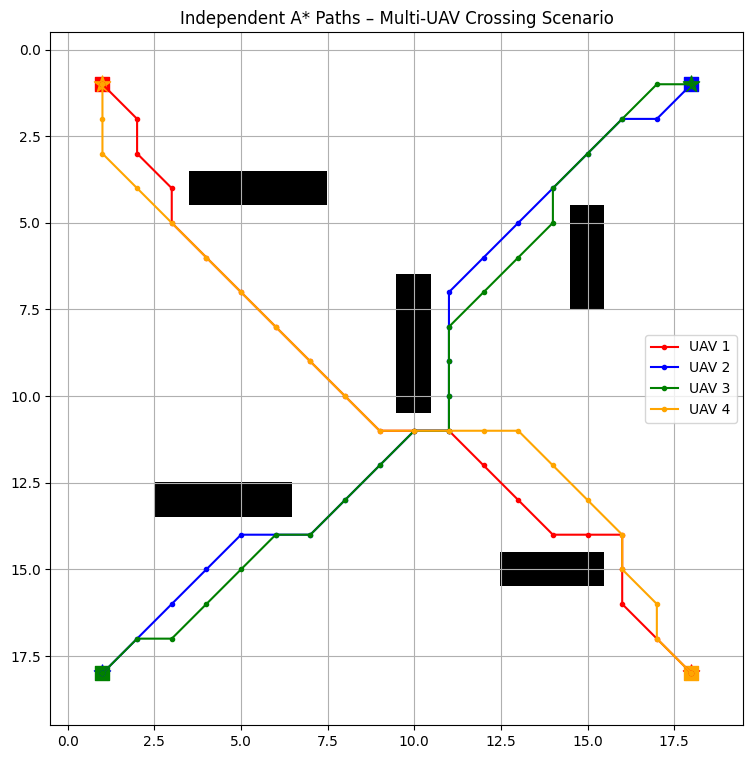

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 9))
plt.imshow(grid, cmap="Greys", origin="upper")

colors = ["red", "blue", "green", "orange"]

for i in range(NUM_UAVS):
    path = astar(starts[i], goals[i])

    rows = [p[0] for p in path]
    cols = [p[1] for p in path]

    plt.plot(cols, rows, color=colors[i],
             marker="o", markersize=3,
             label=f"UAV {i+1}")

    plt.scatter(starts[i][1], starts[i][0],
                marker="s", color=colors[i], s=100)

    plt.scatter(goals[i][1], goals[i][0],
                marker="*", color=colors[i], s=150)

plt.title("Independent A* Paths – Multi-UAV Crossing Scenario")
plt.legend()
plt.grid()
plt.show()

In [22]:
from collections import deque
import numpy as np

def compute_distance_map(grid, goal):
    """
    Computes shortest-path distances from every reachable
    free cell to the goal using BFS.
    """
    rows, cols = grid.shape
    distances = np.full((rows, cols), np.inf)

    queue = deque([goal])
    distances[goal] = 0

    while queue:
        current = queue.popleft()

        for neighbor, move_cost in get_neighbors(current):
            nr, nc = neighbor

            if distances[nr, nc] == np.inf:
                distances[nr, nc] = distances[current] + move_cost
                queue.append(neighbor)

    return distances


distance_maps = [
    compute_distance_map(grid, goal)
    for goal in goals
]

for i in range(NUM_UAVS):
    print(
        f"UAV {i+1}: "
        f"Start distance = {distance_maps[i][starts[i]]:.2f}"
    )

UAV 1: Start distance = 26.38
UAV 2: Start distance = 26.38
UAV 3: Start distance = 26.38
UAV 4: Start distance = 26.38
